# Test neighborhood-level approach:

Note that the method below uses distances in latent space and so is not graph-based anymore

## Prep:

load modules:

In [1]:
%load_ext lab_black

In [2]:
import warnings
import sys
import numpy as np
import pandas as pd
import random
import os
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata

from scipy.stats import ks_2samp, pearsonr  # Why not ks_2samp ?
from scipy.sparse import csr_matrix, save_npz, load_npz
from scipy.spatial.distance import cdist

from sklearn.neighbors import BallTree
from sklearn.metrics import pairwise_distances

from statsmodels.stats.multitest import multipletests

# Set path
notebooks_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
atlas_extension_dir = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
sys.path.append(atlas_extension_dir)

## General settings

In [3]:
# Set global seed // CHANGED
np.random.seed(42)

# Ignore warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

# Set directories
DATA_DIR = os.path.abspath(os.path.join(atlas_extension_dir, "data"))

os.makedirs(os.path.join(notebooks_dir, "Neighborhood-based results"), exist_ok=True)
RESULTS_DIR = os.path.abspath(os.path.join(notebooks_dir, "Neighborhood-based results"))

## Data loading

load files. Below we load the final cellxgene file which is compressed and therefore takes a long time to load... @mariam @daniele you guys probably use a lighter version, so feel free to update path above

In [4]:
adata_ext_full = sc.read_h5ad(
    os.path.join(
        DATA_DIR, "HLCA_full_v1.1_emb.h5ad"
    )  # // CHANGED: from `HLCA_v1.1_full.h5ad`
)  # , backed="r")

## Analysis:

#### Lineage selection

For exploration, subset to a single cell type (specify matching annotation level as well). Eventually, we should do this on the entire embedding.

In [5]:
ct1 = "Fibroblast lineage"  # AT2: level 3; DC2: level 4; Dendritic cells: level 3; Fibroblast lineage: level 2
ct1_level = 2

set parameters:

In [6]:
k = 3000  # still unclear how high to set this

#### Query healthy:
(Cells not run until next header as I save the subsetted anndata object with the added fields locally)

(Adapt and do healthy and disease at the same time, just separate results at the end)

In [7]:
query_dataset = "Sheppard_2020"

Load subsample

In [8]:
# adata_ext_h = sc.read_h5ad(
#    os.path.join(RESULTS_DIR, "Fibroblast_lineage_lvl_2_2000k.h5ad")
# )

Compute subsample

In [9]:
adata_ext_h = (
    adata_ext_full[
        [
            (ref_ann == ct1 or ext_ann == ct1)
            and (c_or_e == "core" or (cond == "Healthy" and ds == query_dataset))
            for ref_ann, ext_ann, c_or_e, cond, ds in zip(
                adata_ext_full.obs[f"ann_level_{ct1_level}"],
                adata_ext_full.obs[f"transf_ann_level_{ct1_level}_label"],
                adata_ext_full.obs.core_or_extension,
                adata_ext_full.obs.lung_condition,
                adata_ext_full.obs.dataset,
            )
        ],
        :,
    ]
    # .to_memory()
    .copy()
)

subset to random set of cells in graph (TO DO: this could ultimately be done more sophisticatedly, check out e.g. Milo or smart subsampling methods. I wouldn't make that a priority for now, we can do during revisions). Not sure yet what fraction is a good number, now taking 1/500 of cells

In [10]:
n_cells = adata_ext_h.shape[0]
SAMPLE_INVERSE_FREQUENCY = 350

print(f"Number of {ct1} cells:", n_cells)
n_cells_to_sample = round(n_cells / SAMPLE_INVERSE_FREQUENCY)
print(f"Sample {n_cells_to_sample} cells")

Number of Fibroblast lineage cells: 34990
Sample 100 cells


In [11]:
cell_subset_idc = random.sample(range(n_cells), k=n_cells_to_sample)
cell_subset_barcodes = adata_ext_h.obs.iloc[cell_subset_idc, :].index

In [12]:
# len(cell_subset_idc), cell_subset_barcodes.shape

Add sign index from previous runs

In [13]:
# significant index to add
# sign_barcode = "P3_5_TAAGTGCAGATGGGTC"
# sign_index = adata_ext_h.obs.index.get_loc(sign_barcode)

# if sign_barcode not in cell_subset_barcodes:
#    cell_subset_idc.append(sign_index)
#    cell_subset_barcodes = pd.Index(cell_subset_barcodes.tolist() + [sign_barcode])
#    n_cells_to_sample = n_cells_to_sample + 1

Sklearn - **no** subsetting to non-zero indices in scanpy distances

In [14]:
# cell_subset_barcodes.shape, len(cell_subset_idc)

In [15]:
adata_ext_h.obs["cell_sampled"] = "no"
adata_ext_h.obs.loc[cell_subset_barcodes, "cell_sampled"] = "yes"

Calculate neighbor graph

In [16]:
# Scanpy neighbors
sc.pp.neighbors(adata_ext_h, use_rep="X", n_neighbors=k, method="umap")  # method="umap"

In [17]:
# Save adata object

# k = 5000 (1 sign. nh)
# adata_ext_h.write(os.path.join(RESULTS_DIR, "Fibroblast_lineage_lvl_2_5000k.h5ad"))

# k = 3000 (1 sign. nh)
adata_ext_h.write(os.path.join(RESULTS_DIR, "Fibroblast_lineage_lvl_2_3000k.h5ad"))

# K = 2000 (0 sign. nh)
# adata_ext_h.write(os.path.join(RESULTS_DIR, "Fibroblast_lineage_lvl_2_2000k.h5ad"))

#### UMAP visualizations

In [18]:
# Compute the UMAP
sc.tl.umap(adata_ext_h)

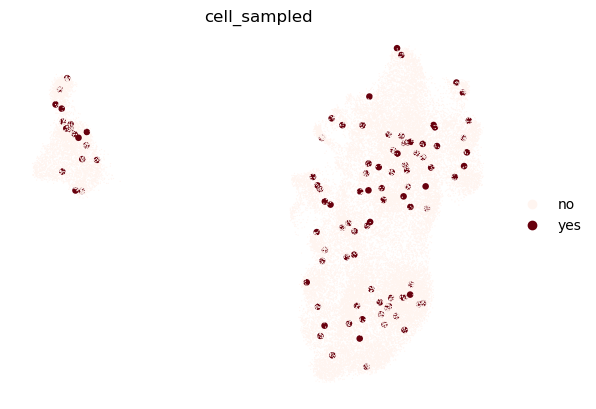

In [19]:
dotsize = 3
sc.pl.umap(
    adata_ext_h,
    color="cell_sampled",
    frameon=False,
    size=[
        30 * dotsize if sampled == "yes" else dotsize
        for sampled in adata_ext_h.obs.cell_sampled
    ],
    palette="Reds",
)

Some further info visualized:

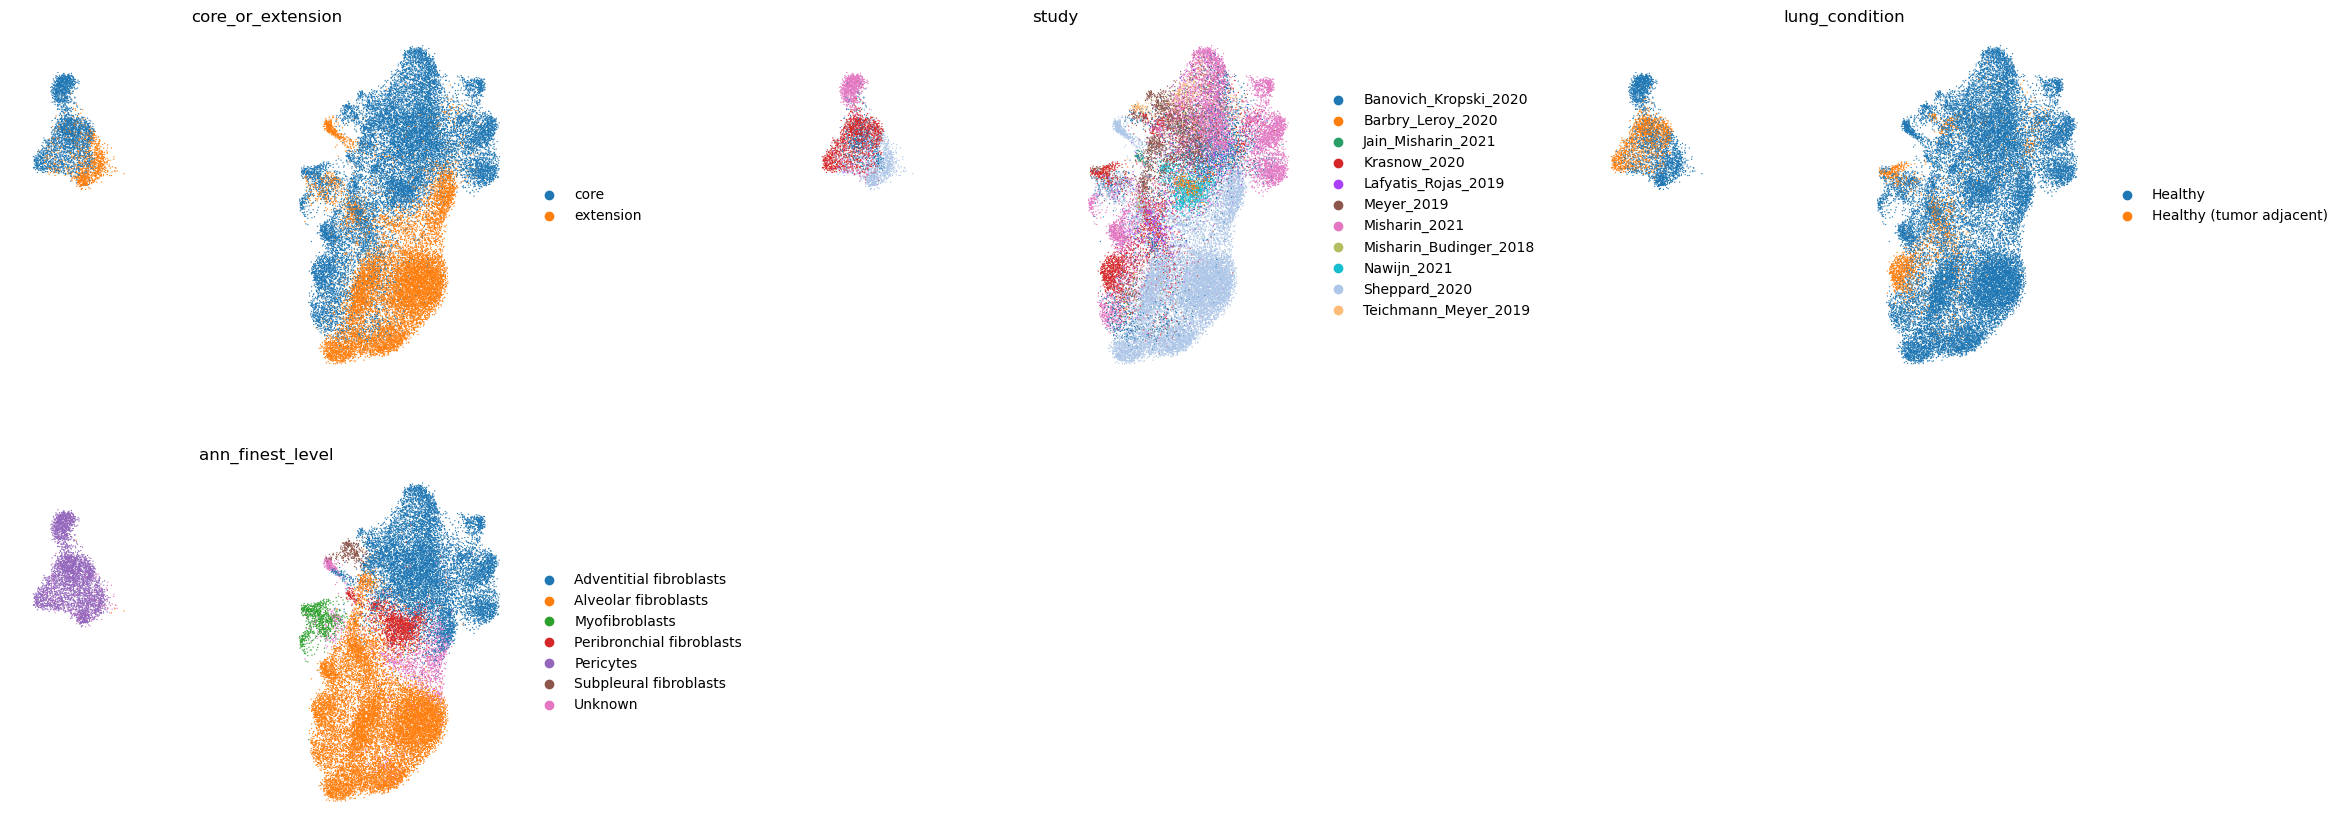

In [20]:
sc.pl.umap(
    adata_ext_h,
    color=["core_or_extension", "study", "lung_condition", "ann_finest_level"],
    frameon=False,
    ncols=3,
    wspace=0.4,
)

#### Extract KNN distances from index cells

In [21]:
# Scanpy distances (ground truth)
dist_ext_subset = adata_ext_h.obsp["distances"][cell_subset_idc, :]

#### Check if connectivities are a superset of distances

In [19]:
def split_indices(sparse_mtx):
    return np.split(sparse_mtx.indices, sparse_mtx.indptr[1:-1])


def is_superset(superset, subset):
    edges_diff = []

    for superset_edges, subset_edges in zip(
        split_indices(superset), split_indices(subset)
    ):
        edges_diff.append(len(np.setdiff1d(subset_edges, superset_edges)))

    return not bool(np.sum(edges_diff))

In [20]:
neighborhood_sub_connectivities = adata_ext_h.obsp["connectivities"][cell_subset_idc, :]
scanpy_sub_distances = adata_ext_h.obsp["distances"][cell_subset_idc, :]

is_superset(neighborhood_sub_connectivities, dist_ext_subset)

True

#### Compute knn distances with different methods

In [20]:
def keep_k_smallest_distances(distances, n_neighbors, exclude_null_dist, sparse=False):
    """
    Selects the closest `n_neighbors` neighbors and sets all the other
    distances to 0.
    """
    distances_copy = distances.copy()

    if exclude_null_dist:
        max_distance = np.max(distances_copy) + 1
        distances_copy[distances_copy == 0] = max_distance

    sorted_distances = np.sort(distances_copy, axis=1)
    mask = distances < sorted_distances[:, n_neighbors - 1].reshape(-1, 1)
    distances *= mask
    if sparse:
        distances = csr_matrix(distances)
    return distances

Check if k smallest distances mapping to non zero connectivities are picked as neighbor distances

In [21]:
nonzero_conn_idc = np.transpose(np.nonzero(neighborhood_sub_connectivities.toarray()))
mask_nonzero_conn = np.zeros_like(dist_ext_subset.toarray(), dtype=float)
mask_nonzero_conn[nonzero_conn_idc[:, 0], nonzero_conn_idc[:, 1]] = 1.0

Sklearn distances

In [22]:
# Euclidean distances w sklearn
dist_ext_subset_sklearn = pairwise_distances(
    adata_ext_h[cell_subset_idc, :].X, adata_ext_h.X
)

In [23]:
dist_ext_subset_sklearn = dist_ext_subset_sklearn * mask_nonzero_conn

In [24]:
dist_ext_subset_sklearn = keep_k_smallest_distances(
    distances=dist_ext_subset_sklearn,
    n_neighbors=k,
    exclude_null_dist=True,
    sparse=False,
)

Scipy distances

In [25]:
# Euclidean distances w scipy
dist_ext_subset_scipy = cdist(adata_ext_h[cell_subset_idc, :].X, adata_ext_h.X)

In [26]:
dist_ext_subset_scipy = dist_ext_subset_scipy * mask_nonzero_conn

In [27]:
dist_ext_subset_scipy = keep_k_smallest_distances(
    distances=dist_ext_subset_scipy,
    n_neighbors=k,
    exclude_null_dist=True,
    sparse=False,
)

#### Check comparability between distance matrices

In [23]:
def visualize_distance_correlation(
    distances1,  # ground-truth
    distances2,  # meth-compare
    method_label,
    set_zero_indices=False,
):
    fig, axs = plt.subplots(figsize=(6, 6))

    d_1 = distances1.flatten().copy()
    d_2 = distances2.flatten().copy()

    # Only display nonzero elements
    if set_zero_indices:
        d_2[np.nonzero(d_1 == 0)[0]] = 0

    axs.scatter(d_1, d_2, s=20, alpha=0.7)

    # Annotate Pearson correlation
    corr, _ = pearsonr(d_1, d_2)
    axs.annotate(f"Pearson corr: {corr:.2f}", xy=(0.05, 0.9), xycoords="axes fraction")

    # axs[row_idx].set_ylabel(f'Row {row_idx}')

    axs.set_title("Euclidean distances")
    axs.set_xlabel("sc_neighbors")
    axs.set_ylabel(f"{method_label}")
    plt.tight_layout()
    plt.show()

Visualize the correlation between scanpy and sklearn/scipy distances. Here I use the neighborhood indexed at 0 as an example. 

As can be observed, there are distances that are set to zero by `sc.pp.neighbors` despite being within the range of the k closest (these cells are not considered neighbors for some reason). Conversely, distances above the upper limit of such a range are non-null in scanpy distances but expectably set to zero in the sklearn and scipy methods alike. 

The correlation is perfect with no outlier cluster on the corner if only the indices of nonzero elements in the scanpy-derived distances are considered for comparison and `n_neighbors` in `keep_k_smallest_distances` is increased by between 300 and 350 more neighbors (i.e. k + [300, 350]; this range is such that every index cell has perfect index correlation with no outlier in the "corners" of the plot, but I can't exclude it could be enlarged).

Hence, some of the `k` neighbors computed by scanpy have higher euclidean distance than the k-th smallest and some cells that have distance less than the k-th smallest have distance = 0 in the scanpy distance matrix (thus not considered neighbors by scanpy? Confusing).

Sklearn - **no** subsetting to non-zero indices in scanpy distances

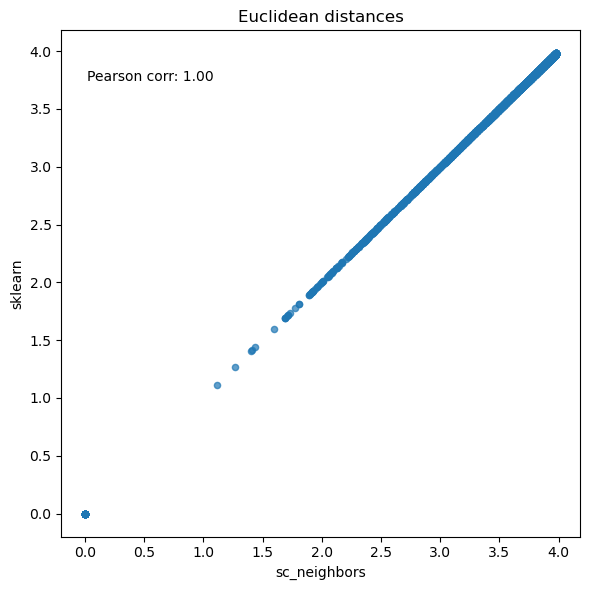

In [24]:
# for nh_idx in range(n_cells_to_sample):
# Perfect correlation for each index cell
visualize_distance_correlation(
    dist_ext_subset[0].toarray(),  # Nh indexed at 0
    dist_ext_subset_sklearn[0],
    method_label="sklearn",
    set_zero_indices=False,
)

Scipy - **no** subsetting to non-zero indices in scanpy distances

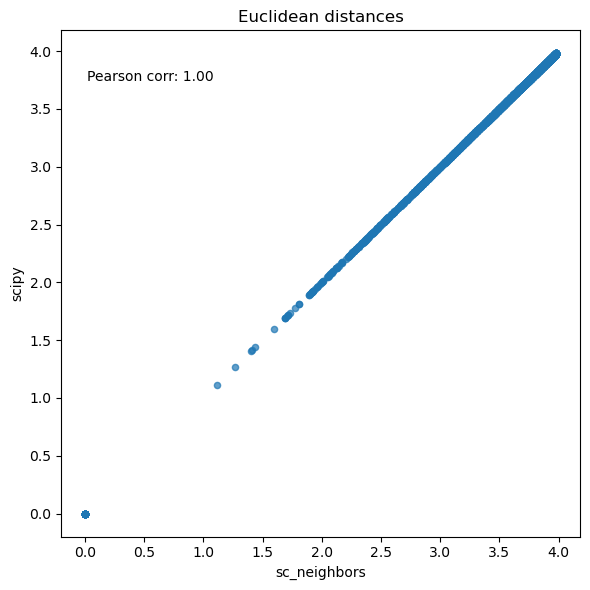

In [25]:
visualize_distance_correlation(
    dist_ext_subset[0].toarray(),
    dist_ext_subset_scipy[0],
    method_label="scipy",
    set_zero_indices=False,
)

#### Neighborhood analysis

In [22]:
def get_highest_column_numbers(matrix, n):
    sorted_indices = np.argsort(matrix, axis=1)[:, ::-1]
    highest_columns = sorted_indices[:, :n]
    return highest_columns

In [23]:
neighbors_idc = get_highest_column_numbers(dist_ext_subset.toarray(), k - 1)

now subset the distance matrix to only the nearest neighbors:

In [24]:
neighbors_distances = dist_ext_subset[
    np.arange(n_cells_to_sample)[:, np.newaxis],
    neighbors_idc,
].toarray()

for each neighbor, get the name of its sample of origin:

In [25]:
neighbors_samples = np.array(adata_ext_h.obs["sample"].values)[neighbors_idc]

calculate mean distance to index cell per sample:

In [26]:
def mean_per_row_group(matrix, grouping):
    unique_groups = np.unique(grouping)
    means_per_group = np.zeros((matrix.shape[0], unique_groups.shape[0]))

    for group_number, group in enumerate(unique_groups):
        mask = grouping == group
        group_sum = np.nansum(matrix * mask, axis=1)
        group_count = np.nansum(mask, axis=1)
        mean_per_row = group_sum / group_count
        means_per_group[:, group_number] = mean_per_row
    return unique_groups, means_per_group

In [27]:
samples_ext, means_per_sample_ext = mean_per_row_group(
    neighbors_distances, neighbors_samples
)

/var/folders/m9/z5ypwpm102g0228qlc00jsvh0000gn/T/ipykernel_95632/3062662242.py:9: RuntimeWarning: invalid value encountered in divide
  mean_per_row = group_sum / group_count


store results in pandas dataframe:

In [28]:
res_healthy = pd.DataFrame(
    data=means_per_sample_ext.T, index=samples_ext, columns=cell_subset_barcodes
)

##### query disease:

In [29]:
# ...to do, probably just include from the start above

#### Results healthy:

(Code below is maybe not the most efficient, but it's nothing memory-heavy so only need to change if it's confusing to you)

In [29]:
res_healthy.shape

(129, 100)

prepare dataframe for split boxplot (we need two columns rather than a dataframe with rowsxcolumns)

In [30]:
res_healthy_flat = res_healthy.unstack()
res_healthy_flat = pd.DataFrame(res_healthy_flat)
res_healthy_flat.reset_index(level=1, inplace=True)
res_healthy_flat.rename(
    columns={"level_1": "sample", 0: "mean_distance_to_index_cell"}, inplace=True
)
res_healthy_flat["neighborhood"] = res_healthy_flat.index
res_healthy_flat["index_cell_origin"] = adata_ext_h.obs.loc[
    res_healthy_flat.neighborhood, "core_or_extension"
]
res_healthy_flat["neighborhood, cell type, ref or q"] = [
    f"{nh}, {adata_ext_h.obs.loc[nh,'ann_finest_level']} ({adata_ext_h.obs.loc[nh,'core_or_extension']})"
    for nh in res_healthy_flat.neighborhood
]
res_healthy_flat["ref_or_q"] = "ref"
q_samples = adata_ext_h.obs.loc[
    adata_ext_h.obs.core_or_extension == "extension", "sample"
].unique()
res_healthy_flat.loc[res_healthy_flat["sample"].isin(q_samples), "ref_or_q"] = "q"

Now plot:

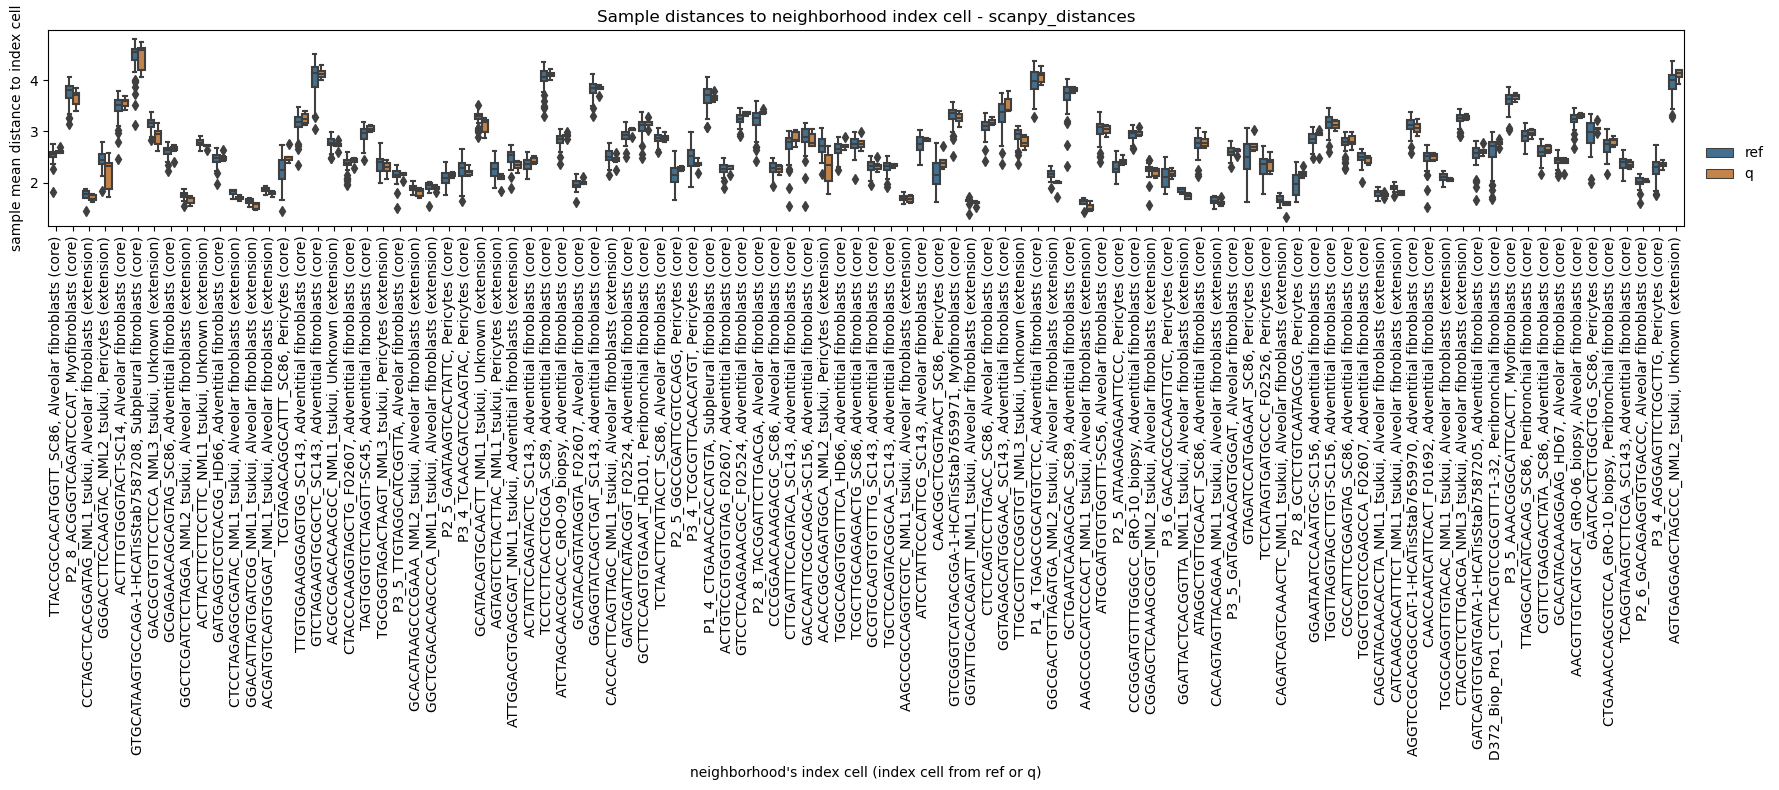

In [31]:
fig, ax = plt.subplots(figsize=(18, 8))
sns.boxplot(
    data=res_healthy_flat,
    x="neighborhood, cell type, ref or q",
    y="mean_distance_to_index_cell",
    ax=ax,
    hue="ref_or_q",
    saturation=0.5,
)
"""
sns.stripplot(
    data=res_healthy_flat,
    x="neighborhood, cell type, ref or q",
    y="mean_distance_to_index_cell",
    ax=ax,
    hue="ref_or_q",
    dodge=True,
    size=1,
    color="black",
)
"""
ax.tick_params(axis="x", rotation=90)
leg = plt.legend(loc=(1.01, 0.2), frameon=False, title="")
leg._legend_box.align = "left"
ax.set_xlabel("neighborhood's index cell (index cell from ref or q)")
ax.set_ylabel("sample mean distance to index cell")
ax.set_title("Sample distances to neighborhood index cell - scanpy_distances")
plt.tight_layout()
plt.show()

Perform KS-test for every neighborhood

In [32]:
neighborhood_stats = pd.DataFrame(
    index=cell_subset_barcodes, columns=["KS_stat", "pvalue"]
)

Collect query samples that are sorrounded by query only (`ks_2samp()` can't be run on those)

In [ ]:
query_batch_affected = {}

Now calculate stats:

In [33]:
# loop through neighborhoods
for nh_idc, index_cell in enumerate(cell_subset_barcodes):
    # check if index cell is from query or ref
    index_source = adata_ext_h.obs.loc[index_cell, "core_or_extension"]

    # extract mean distances from query samples to index cell.
    # drop nas, i.e. ignore samples not observed in the neighborhood
    query_sample_results = res_healthy_flat.loc[
        [
            nh == index_cell and ref_or_q == "q"
            for nh, ref_or_q in zip(
                res_healthy_flat.neighborhood, res_healthy_flat.ref_or_q
            )
        ],
        "mean_distance_to_index_cell",
    ].dropna()
    # get same results for reference samples
    ref_sample_results = res_healthy_flat.loc[
        [
            nh == index_cell and ref_or_q == "ref"
            for nh, ref_or_q in zip(
                res_healthy_flat.neighborhood, res_healthy_flat.ref_or_q
            )
        ],
        "mean_distance_to_index_cell",
    ].dropna()

    # KS tests - one-sided
    if index_source == "core":
        if query_sample_results.empty:
            continue # not necessarily alarming - wouldn't add a container for those
        # test if query distances are larger than reference:
        neighborhood_stats.loc[index_cell, :] = ks_2samp(
            query_sample_results.values,
            ref_sample_results.values,
            alternative="greater",
        )
    elif index_source == "extension":
        if query_sample_results.empty:
            # only ref samples around query - not alarming
            continue
        elif ref_sample_results.empty:
            # only query samples around query
            unique_elements, counts = np.unique(
                neighbors_samples[nh_idc], return_counts=True
            )
            query_batch_affected[f"{index_cell}"] = dict(zip(unique_elements, counts))
            continue
        # test if query distances are smaller than reference:
        neighborhood_stats.loc[index_cell, :] = ks_2samp(
            query_sample_results.values,
            ref_sample_results.values,
            alternative="less",
        )

In [34]:
query_batch_affected

{}

Perform multiple testing correction (benjamini-hochberg FDR):

In [35]:
neighborhood_stats["pvalue_corr"] = multipletests(
    neighborhood_stats.pvalue.values, method="fdr_bh"
)[1]

Add KS test results to adata_ext_h for visualization, and add some further information (binary significant/not significant, and -log10 pvalues; -np.log10(0.05) = 1.301)

In [36]:
adata_ext_h.obs["KS_test_corr_pvals"] = 1.0
adata_ext_h.obs.loc[
    neighborhood_stats.index, "KS_test_corr_pvals"
] = neighborhood_stats.pvalue_corr
adata_ext_h.obs["KS_test_sign"] = "Not sign."
adata_ext_h.obs["KS_test_sign"] = np.where(
    adata_ext_h.obs.KS_test_corr_pvals < 0.05, "Sign.", adata_ext_h.obs.KS_test_sign
)
adata_ext_h.obs["-log10(KS_test_corr_pvals)"] = -np.log10(
    adata_ext_h.obs.KS_test_corr_pvals.astype(float)
)

In [37]:
# scanpy
adata_ext_h[adata_ext_h.obs["-log10(KS_test_corr_pvals)"] > 0].obs[
    ["-log10(KS_test_corr_pvals)", "core_or_extension"]
].sort_values(by="-log10(KS_test_corr_pvals)")

# P3_5_TAAGTGCAGATGGGTC is significant (p-val = 0.037814) and a `core` index cell

,-log10(KS_test_corr_pvals),core_or_extension


Now visualize results (put sampled cells at the end of the anndata (i.e. lowest rows) to make the visualization cleaner, with big dots=index cells on top)

In [38]:
def get_custom_cmap(adata, sign_stat_col):
    # Check unique values in the specified column
    unique_values = adata.obs[sign_stat_col].dropna().unique()

    # If there is only one unique value, return a categorical colormap
    if len(unique_values) == 1:
        return sns.light_palette((1, 0.85, 0.85), as_cmap=True)

    # Otherwise, return a custom colormap with pale red for 0 and darker red for 1
    custom_cmap = sns.blend_palette([sns.light_palette("red")[0], "red"], as_cmap=True)
    return custom_cmap

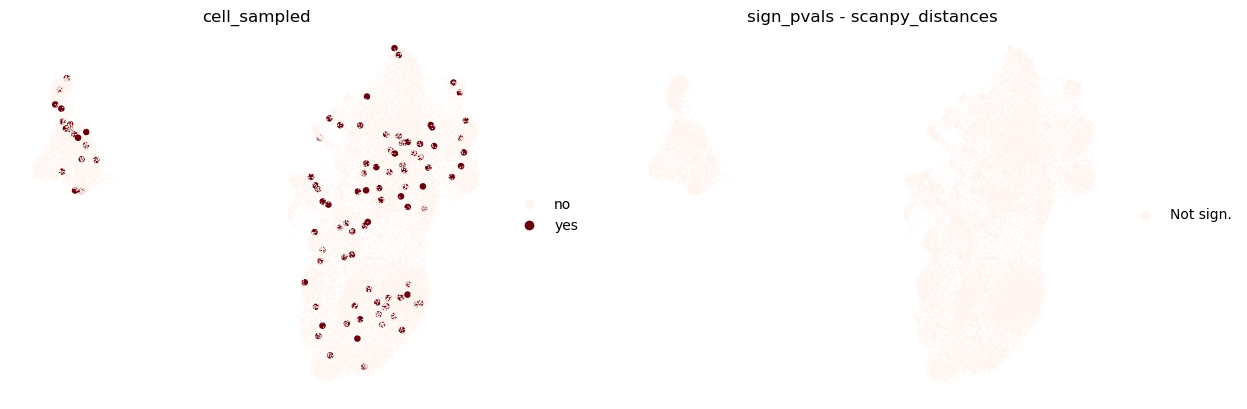

In [39]:
dotsize = 3

sc.pl.umap(
    adata_ext_h,
    color=["cell_sampled", "KS_test_sign"],
    frameon=False,
    size=[
        30 * dotsize if sampled == "yes" else dotsize
        for sampled in adata_ext_h.obs.cell_sampled
    ],
    cmap="Reds",  # get_categorical_cmap(adata_ext_h, "KS_test_sign"),
    palette="Reds",
    title=["cell_sampled", "sign_pvals - scanpy_distances"],
)

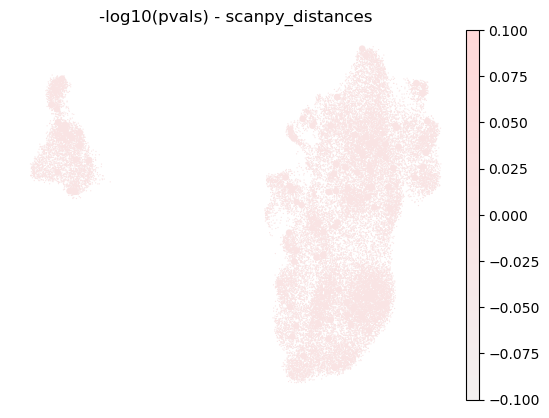

In [40]:
sc.pl.umap(
    adata_ext_h,
    color=["-log10(KS_test_corr_pvals)"],
    frameon=False,
    size=[
        30 * dotsize if sampled == "yes" else dotsize
        for sampled in adata_ext_h.obs.cell_sampled
    ],
    cmap=get_custom_cmap(adata_ext_h, "-log10(KS_test_corr_pvals)"),
    palette="Reds",
    title="-log10(pvals) - scanpy_distances",
)

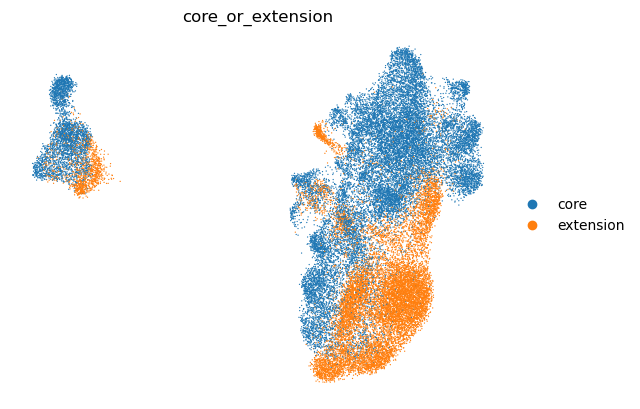

In [41]:
sc.pl.umap(adata_ext_h, color="core_or_extension", frameon=False)